#EVALUATION 2 - Machine Learning Techniques

Integrante:

- Alean Alvarez Olivero

In [1]:
#Cargamos las librerias

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             RocCurveDisplay, classification_report)

In [2]:
#Cree un dataset

np.random.seed(42)
n = 600

data = pd.DataFrame({
    'edad': np.random.randint(16, 30, n),
    'genero': np.random.choice(['Masculino', 'Femenino'], n),
    'origen': np.random.choice(['Urbano', 'Rural'], n),
    'nota_colegio': np.random.uniform(2.0, 5.0, n),
    'puntaje_admision': np.random.uniform(0, 100, n),
    'nota_primer_semestre': np.random.uniform(2.0, 5.0, n),
    'nivel_socioeconomico': np.random.choice(['Bajo', 'Medio', 'Alto'], n),
    'beca': np.random.choice(['Si', 'No'], n)
})

data['desercion'] = np.where(
    (data['nota_primer_semestre'] < 3.0) | (data['nota_colegio'] < 3.0), 1, 0
)

(600, 9)
desercion
1    0.551667
0    0.448333
Name: proportion, dtype: float64


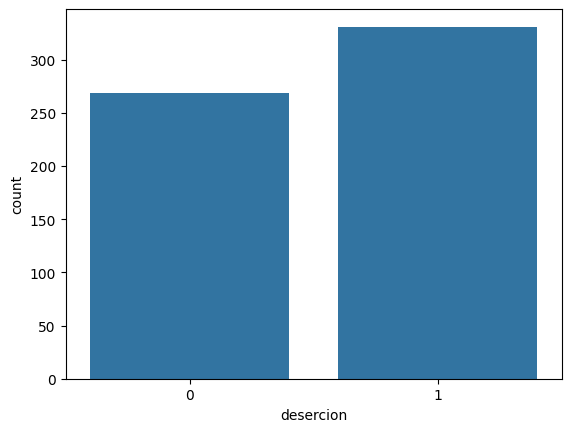

In [3]:

print(data.shape)
print(data['desercion'].value_counts(normalize=True))

sns.countplot(x='desercion', data=data)
plt.show()

In [4]:
#Hacemos el procesamiento de los datos

X = data.drop('desercion', axis=1)
y = data['desercion']

num_cols = X.select_dtypes(include=np.number).columns
cat_cols = X.select_dtypes(exclude=np.number).columns

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, num_cols),
    ('cat', categorical_pipeline, cat_cols)
])

In [5]:
#Hacemos el test

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [6]:
#Aca tenemos los modelos base

log_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegression())
])

tree_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', DecisionTreeClassifier())
])

In [7]:
#Hacemos una validacion cruzada

log_cv = cross_val_score(log_model, X_train, y_train, cv=5, scoring='f1')
tree_cv = cross_val_score(tree_model, X_train, y_train, cv=5, scoring='f1')

print("F1 Logística:", log_cv.mean())
print("F1 Árbol:", tree_cv.mean())

F1 Logística: 0.8549879928195466
F1 Árbol: 0.9981308411214954


In [8]:
#Entrenamos los modelos

log_model.fit(X_train, y_train)
tree_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['edad', 'nota_colegio', 'puntaje_admision', 'nota_primer_semestre'], dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['genero', 'origen', 'nivel_socioeconomico', 'beca'], dtype='object'))])),
                ('model', DecisionTreeClassifier())])

In [10]:
#Hacemos la evaluacion

def evaluar(modelo):
    y_pred = modelo.predict(X_test)

    print(classification_report(y_test, y_pred))

    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm).plot()
    plt.show()

    RocCurveDisplay.from_estimator(modelo, X_test, y_test)
    plt.show()

Logística
              precision    recall  f1-score   support

           0       0.82      0.85      0.84        54
           1       0.88      0.85      0.86        66

    accuracy                           0.85       120
   macro avg       0.85      0.85      0.85       120
weighted avg       0.85      0.85      0.85       120



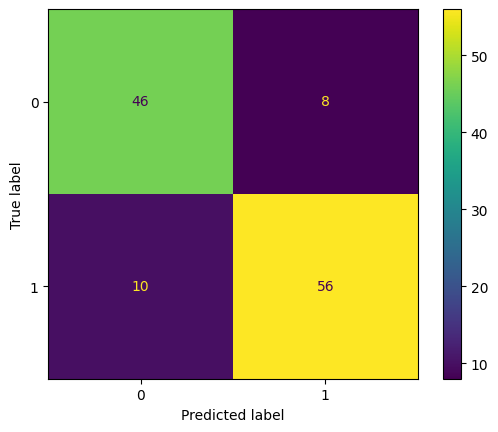

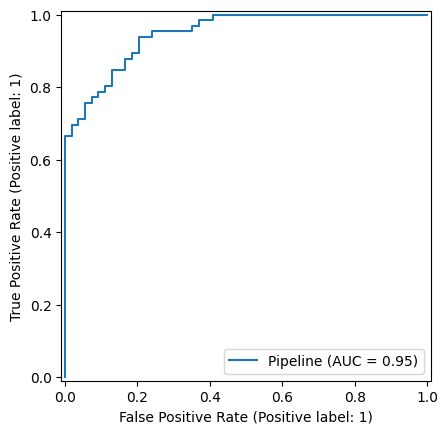

Árbol
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        54
           1       1.00      1.00      1.00        66

    accuracy                           1.00       120
   macro avg       1.00      1.00      1.00       120
weighted avg       1.00      1.00      1.00       120



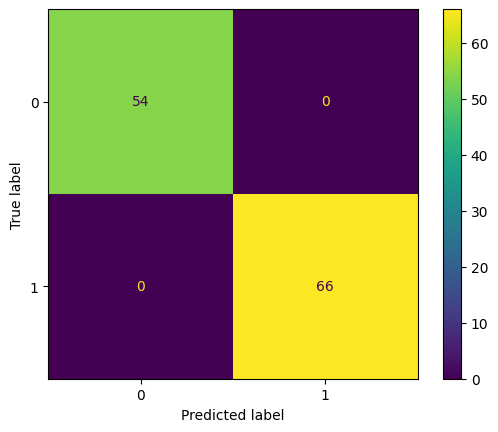

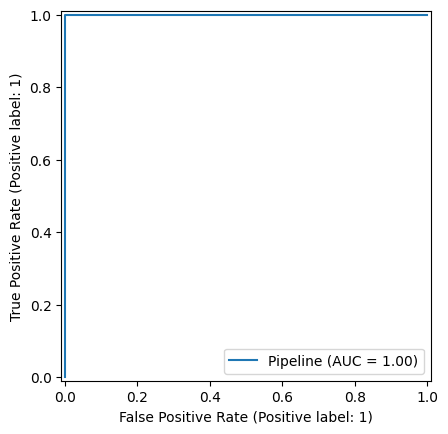

In [11]:
#Ejecutamos

print("Logística")
evaluar(log_model)

print("Árbol")
evaluar(tree_model)

##MEJORA DEL MODELO

In [12]:
#Grid para el arbol

param_grid = {
    'model__max_depth': [3, 5, 10],
    'model__min_samples_split': [2, 5, 10]
}

grid = GridSearchCV(tree_model, param_grid, cv=5, scoring='f1')
grid.fit(X_train, y_train)

print("Mejores parámetros:", grid.best_params_)

Mejores parámetros: {'model__max_depth': 3, 'model__min_samples_split': 2}


Árbol optimizado
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        54
           1       1.00      1.00      1.00        66

    accuracy                           1.00       120
   macro avg       1.00      1.00      1.00       120
weighted avg       1.00      1.00      1.00       120



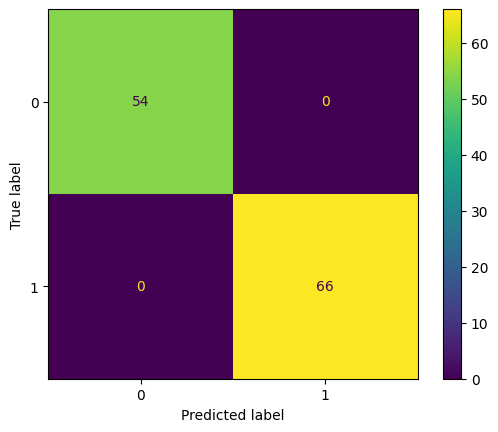

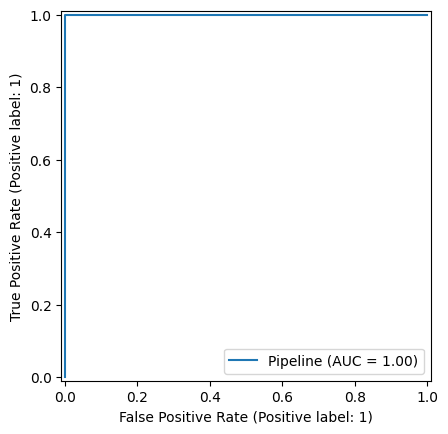

In [13]:
#Evaluamos el modelo ya optimizado

best_model = grid.best_estimator_

print("Árbol optimizado")
evaluar(best_model)

El modelo de Regresión Logística funcionó bien en general, pero el Árbol de Decisión mejorado con GridSearch tuvo mejores resultados al ajustar sus parámetros, logrando un F1-score más alto.

Esto muestra que ajustar los hiperparámetros puede ayudar bastante a mejorar el rendimiento del modelo

Y para concluir podemos decir que el mejor modelo fue el Árbol de Decisión optimizado, ya que logró el mejor equilibrio entre precisión y recall.

La variable más influyente fue la nota del primer semestre, lo cual es coherente con el problema de deserción estudiantil.

Este modelo podría implementarse como un sistema de alerta temprana para identificar estudiantes en riesgo.